# 11 Disease spreading
## Transmission, mortality, and temporary immunity

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for section 11.2-11.3 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

Let's see how the different parameters ($\beta$, $\gamma$) affect the epidemic.

Then, we relax the assumptions of permanent immunity and no mortality (extension of the SIR model)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path
import sys
sys.path.insert(0, '../11_modules')
import disease_spreading as ds

## 11.2 Disease transmission as a function of the infection rate

In the agent-based SIR model:

- the epidemic ends when $I=0$

As we have permanent immunity:

- the **final number of recovered agents** ($R_\infty$) is the number of infections occurred.  

In the ODE-based SIR model, $R_\infty$ depends only on the ratio $\beta/\gamma$.

*Is this also true for the agent-based SIR model?*

### Exercise 11.2

Let's run a simulation and record the final number of recovered agents.

In [3]:
N = 1000
L = 100
d = 0.8

f = 0.01

beta = 0.6
gamma = 0.01

result = ds.run_sir(
    n_agents=N, side=L, infected_fraction=f, 
    d=d, beta=beta, gamma=gamma, 
    max_steps=6000
)

print(f"Extinct: {result['ended_by_extinction']}")

print(f"R at the end: {result['R'][-1]}")

print(f"Steps: {result['steps']}")

Extinct: True
R at the end: 939
Steps: 1391


Let's have a series of *independent* runs and use a mean and a standard error. 

In [4]:
repetitions = 30
sizes = []
for run in range(repetitions):
    result = ds.run_sir(
        n_agents=N, side=L, infected_fraction=f, 
        d=d, beta=beta, gamma=gamma, 
        max_steps=6000
    )
    if result["ended_by_extinction"]:
        sizes.append(result["R"][-1])

print("Completed epidemics:", len(sizes), "of", repetitions)

Completed epidemics: 30 of 30


In [5]:
if sizes:
    mean_size = np.mean(sizes)
    se_size = (
        np.std(sizes, ddof=1) / np.sqrt(len(sizes)) 
        if len(sizes) > 1 else np.nan
    )
    print(f"Mean final R: {mean_size:.1f};"
          f" standard error: {se_size:.1f}")

Mean final R: 939.1; standard error: 2.7


Now, let's fix $\gamma$ and scan several $\beta$ values.

In [6]:
beta_values = np.linspace(0.0, 1.0, 7)
gamma_values = [0.01, 0.02]

repetitions = 10

mean_R = np.full((len(gamma_values), len(beta_values)), np.nan)

sem_R = np.full_like(mean_R, np.nan)


In [7]:
for row, gamma in enumerate(gamma_values):
    for col, beta in enumerate(beta_values):
        samples = []
        for _ in range(repetitions):
            result = ds.run_sir(
                n_agents=N, side=L, infected_fraction=f, 
                d=d, beta=beta, gamma=gamma, 
                max_steps=6000
            )
            if result["ended_by_extinction"]:
                samples.append(result["R"][-1])
        if len(samples) == repetitions:
            mean_R[row, col] = np.mean(samples)
            if repetitions > 1:
                sem_R[row, col] = (
                    np.std(samples, ddof=1) / np.sqrt(repetitions)
                )
                
print(
    "Incomplete parameter points:", 
    np.count_nonzero(np.isnan(mean_R))
)

Incomplete parameter points: 0


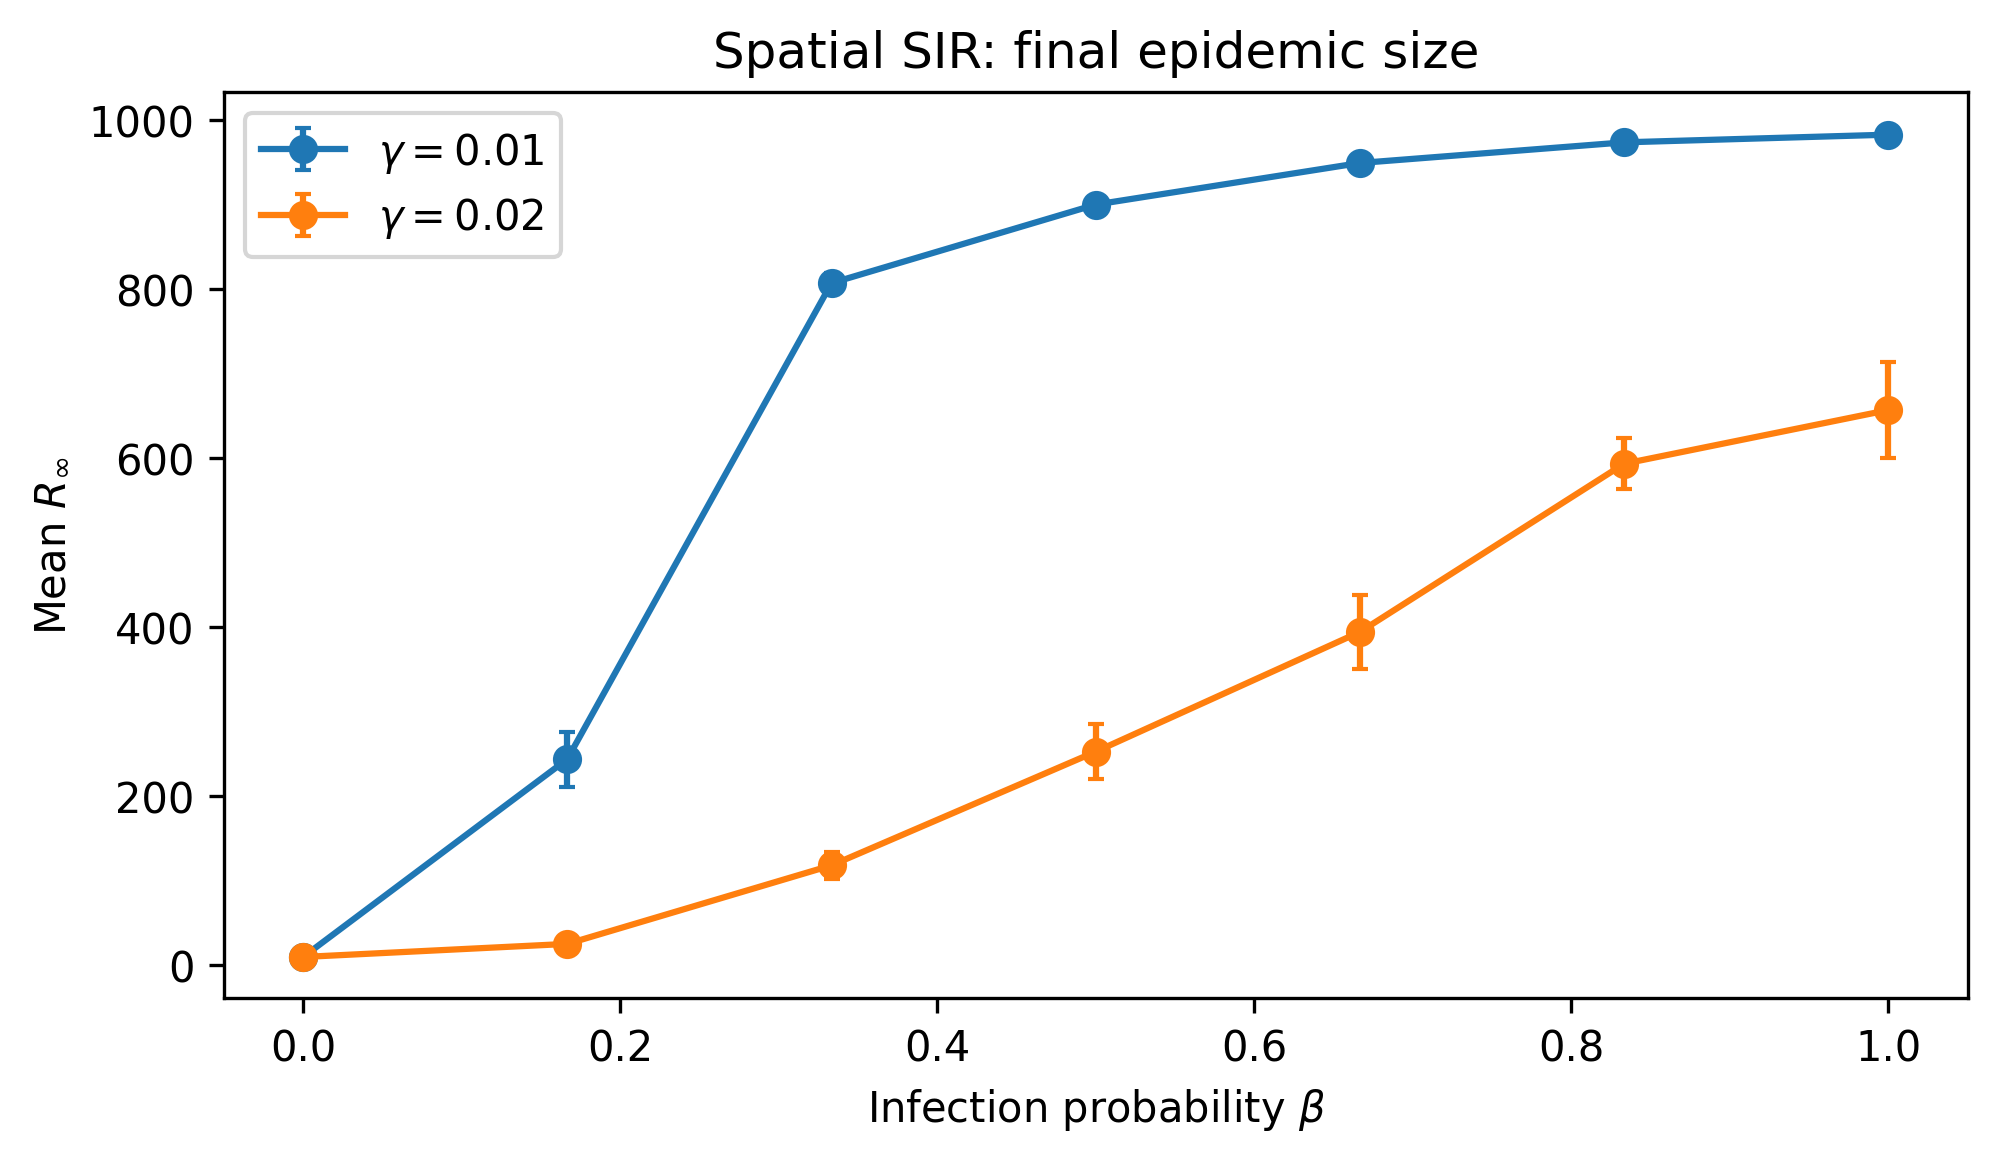

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4), dpi=300)

for row, gamma in enumerate(gamma_values):
    ax.errorbar(
        beta_values, mean_R[row], yerr=sem_R[row],
        marker="o", capsize=2, label=fr"$\gamma={gamma}$"
    )
ax.set(
    xlabel=r"Infection probability $\beta$", 
    ylabel=r"Mean $R_\infty$",
    title="Spatial SIR: final epidemic size"
)
ax.legend()
plt.show()

Let's plot $R_{\infty}$ versus $\beta/\gamma$. 

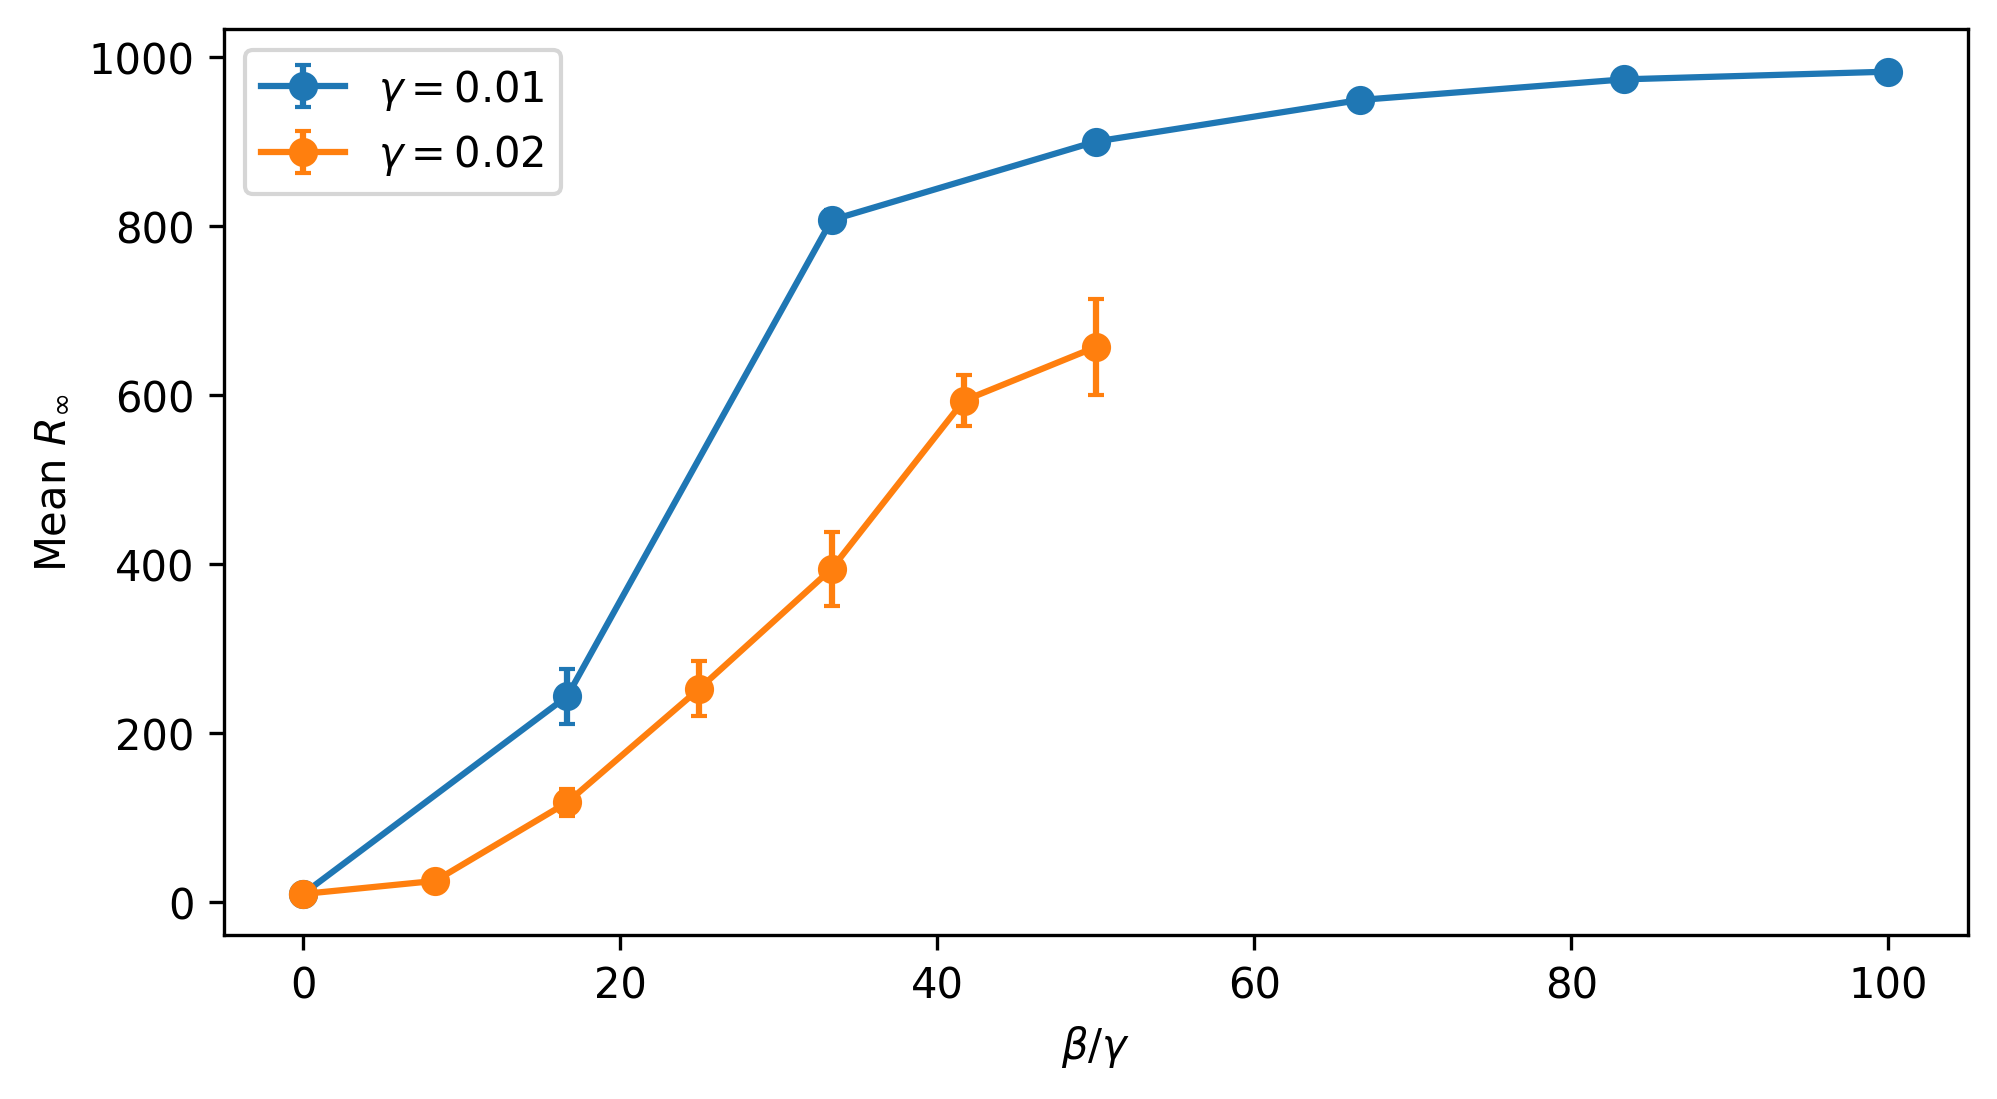

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4), dpi=300)
for row, gamma in enumerate(gamma_values):
    ax.errorbar(
        beta_values / gamma, mean_R[row], yerr=sem_R[row],
        marker="o", capsize=2, label=fr"$\gamma={gamma}$"
    )
ax.set(
    xlabel=r"$\beta/\gamma$", 
    ylabel=r"Mean $R_\infty$"
)
ax.legend()
plt.show()

Let's try to reproduce Fig. 11.5 of the book.

We vary $\beta$ and the target ratio $k=\beta/\gamma$ independently, then calculate $\gamma=\beta/k$. 


In [10]:
beta_grid = np.linspace(0.1, 0.9, 9)
ratio_grid = np.linspace(10, 90, 9)
phase = np.full((len(ratio_grid), len(beta_grid)), np.nan)
phase_repetitions = 5

In [11]:
for row, ratio in enumerate(ratio_grid):
    print(f'row = {row} of {len(ratio_grid)}')
    for col, beta in enumerate(beta_grid):
        gamma = beta / ratio
        values = []
        for _ in range(phase_repetitions):
            result = ds.run_sir(
                n_agents=N, side=L, 
                d=d, beta=beta, gamma=gamma, 
                max_steps=6000
            )
            if result["ended_by_extinction"]:
                values.append(result["R"][-1])
        if len(values) > 2:
            phase[row, col] = np.mean(values)

row = 0 of 9
row = 1 of 9
row = 2 of 9
row = 3 of 9
row = 4 of 9
row = 5 of 9
row = 6 of 9
row = 7 of 9
row = 8 of 9


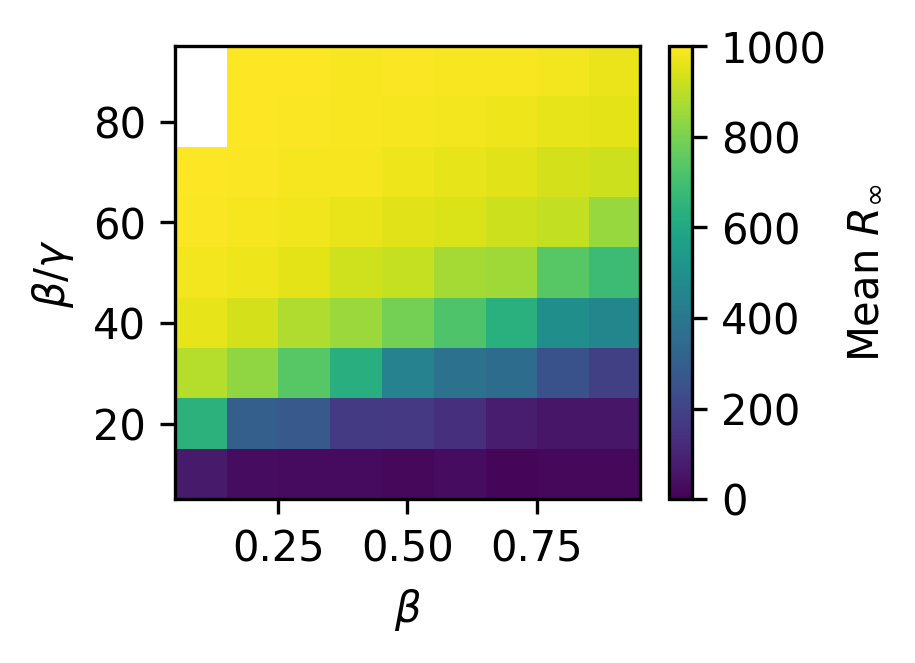

In [12]:
plt.figure(figsize=(2.5, 2), dpi=300)

db = beta_grid[1] - beta_grid[0]
dr = ratio_grid[1] - ratio_grid[0]

plt.imshow(
    phase, 
    origin="lower", 
    aspect="auto",
    extent=[
        beta_grid[0] - db / 2, beta_grid[-1] + db / 2, 
        ratio_grid[0] - dr / 2, ratio_grid[-1] + dr / 2
    ],
    vmin=0, 
    vmax=N
)
plt.colorbar(label=r"Mean $R_\infty$")
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\beta/\gamma$")
plt.show()

## 11.3 Extended SIR models

Let's implement:
- **mortality** (Exercise 11.3)
- **temporary immunity** (Exercise 11.4).

### Exercise 11.3

**Mortality: SIRD**

We have to add the state: $D=3$ (deceased agent).

Rules:

- An already infected agent dies with probability $\mu$ this step.
- Otherwise, it recovers with conditional probability $\gamma$.
- Otherwise, it stays infected.

Thus:
$$P(I\to D)=\mu$$ 
and 
$$P(I\to R)=(1-\mu)\,\gamma$$

Infection attempts occur **before** any death or recovery.

Let's see how it works for a small set of agents

In [13]:
tiny_status = np.array([1, 1, 1, 0, 2], dtype=np.int8)

old_infected = tiny_status == 1

mu_test = 0.2
gamma_test = 0.3

trial_numbers = np.random.random(len(tiny_status))

dying = old_infected & (trial_numbers < mu_test)

recovering = (
    old_infected & (trial_numbers >= mu_test) 
    & (trial_numbers < mu_test + (1-mu_test)*gamma_test)
)

tiny_status[dying] = 3
tiny_status[recovering] = 2

print("Example new states:", tiny_status)

Example new states: [3 3 2 0 2]


In [14]:
N = 1000
L = 100
d = 0.8

f = 0.01

beta = 0.6
gamma = 0.01
mu = 0.005

trial = ds.run_sir(
    n_agents=N, side=L, infected_fraction=f,
    d=d, beta=beta, gamma=gamma, mu=mu, 
    max_steps=6000
)

print(f"Final D: {trial['D'][-1]}")
print(f"Extinct: {trial['ended_by_extinction']}")
assert np.all(
    trial["S"] + trial["I"] + trial["R"] + trial["D"] == 1000
)

Final D: 258
Extinct: True


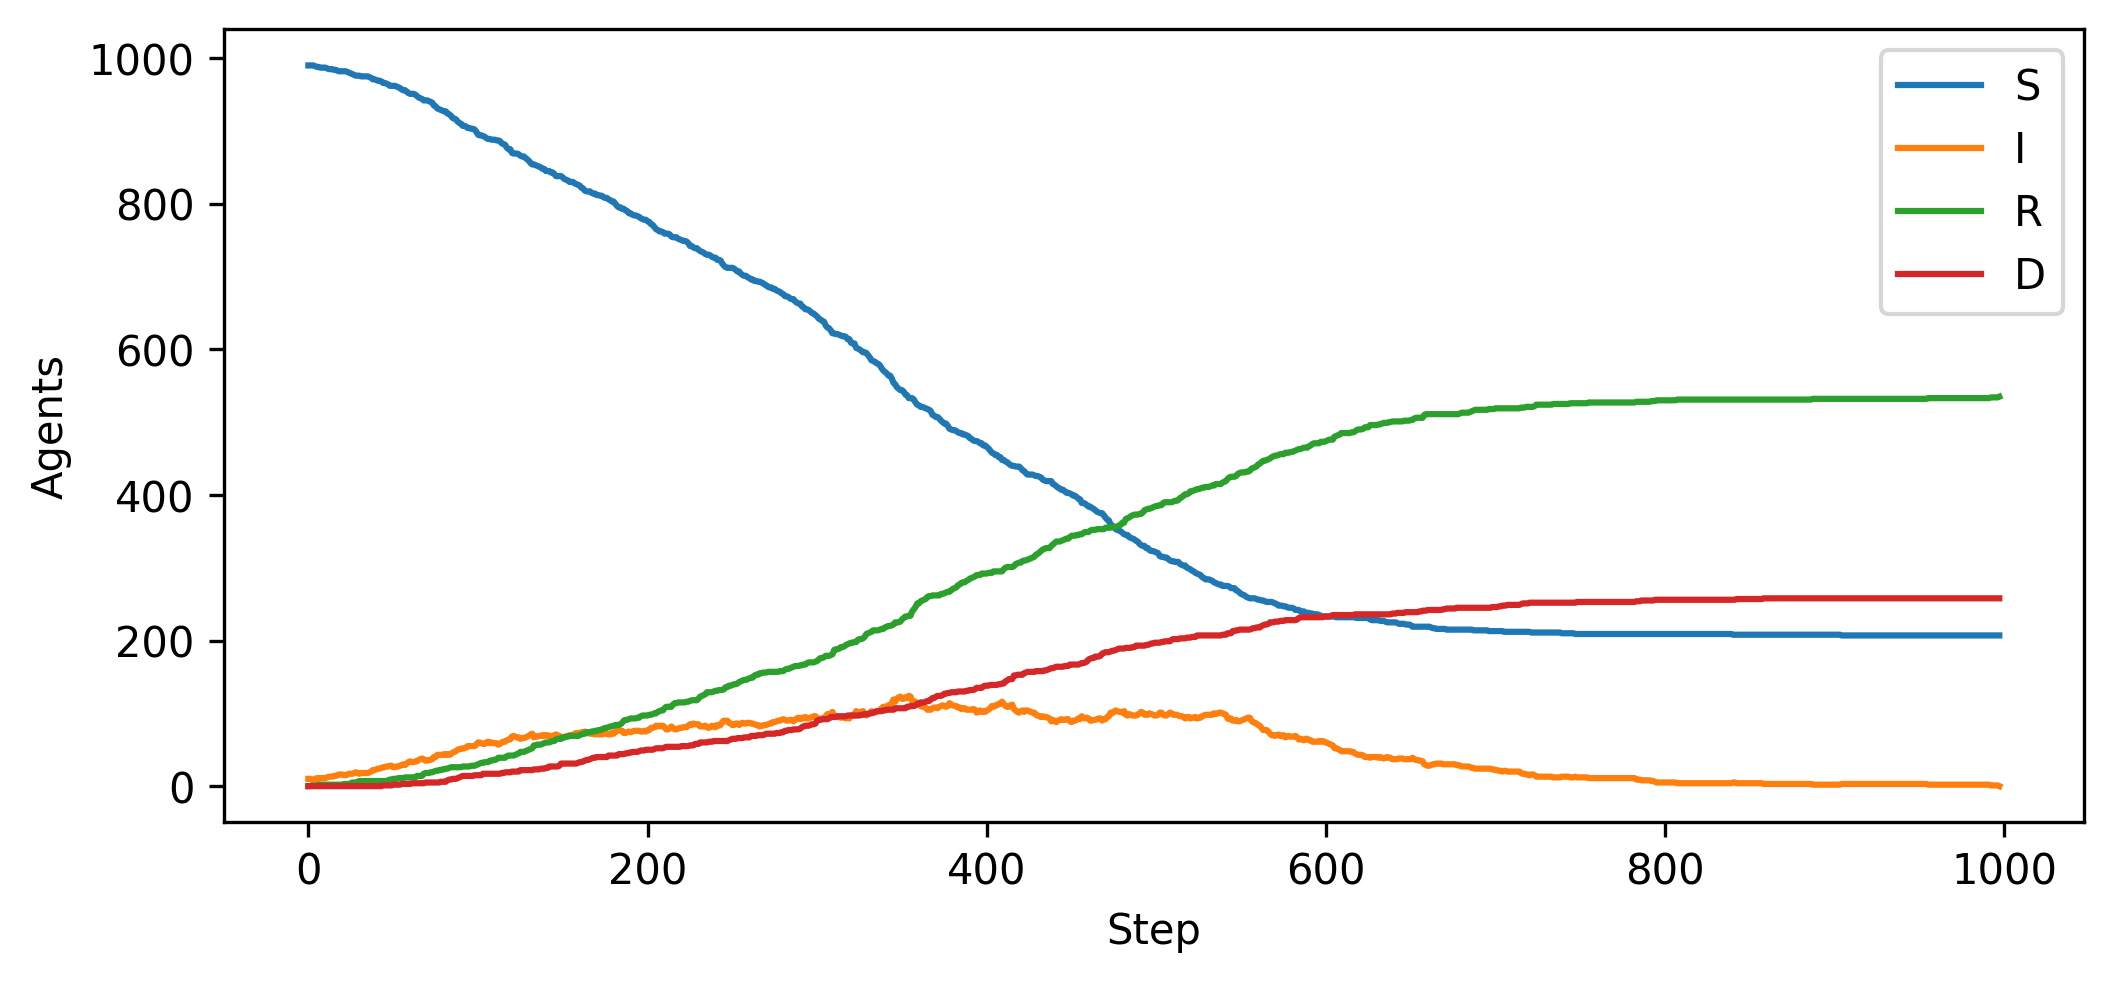

In [15]:
plt.figure(figsize=(8, 3.5), dpi=300)

for name in "SIRD":
    plt.plot(trial["time"], trial[name], label=name)
plt.xlabel("Step")
plt.ylabel("Agents")
plt.legend()
plt.show()

Let's explore the **mortality paradox** 

Is $D_\infty$ increase monotonically with $\mu$?

At $\mu=0$, deaths are necessarily zero. 

At very high $\mu$, newly infected agents tend to die before transmitting for many additional steps, which can limit spread. 

What happens for intermediate values of $\mu$? 

In [16]:
N = 1000
L = 100
d = 0.8

f = 0.01

beta = 0.6
gamma = 0.01

mu_values = np.hstack(
    (np.linspace(0, 0.08, 5), np.linspace(0.1, 1, 9))
)
mu_repetitions = 10
mean_deaths = []
sem_deaths = []
for mu in mu_values:
    deaths = []
    recovered = []
    infections = []
    for _ in range(mu_repetitions):
        run = ds.run_sir(
            n_agents=N, side=L, infected_fraction=f,
            d=d, beta=beta, gamma=gamma, mu=mu, 
            max_steps=6000
        )
        if run["ended_by_extinction"]:
            deaths.append(run["D"][-1])
    if len(deaths) == mu_repetitions:
        mean_deaths.append(np.mean(deaths))
        sem_deaths.append(
            np.std(deaths, ddof=1) / np.sqrt(mu_repetitions)
        )
    else:
        mean_deaths.append(np.nan)
        sem_deaths.append(np.nan)
        

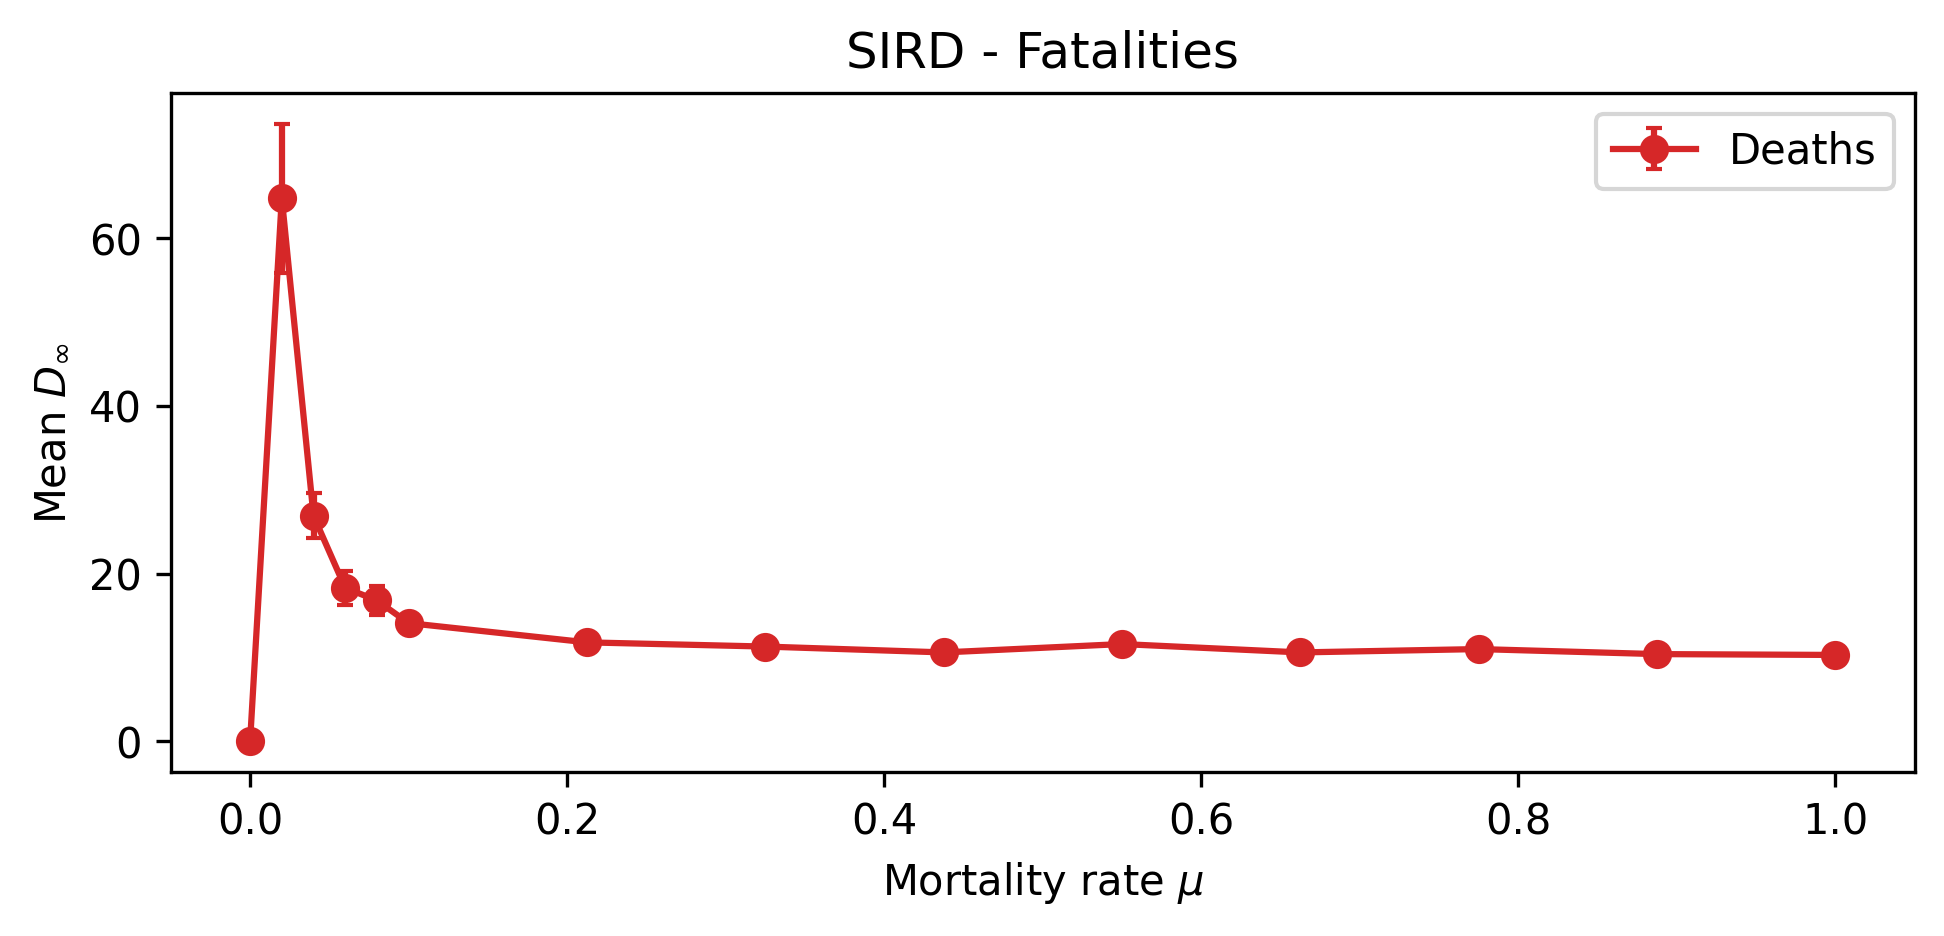

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3), dpi=300)

plt.errorbar(
    mu_values, mean_deaths, yerr=sem_deaths,
    marker="o", capsize=2, color="C3", 
    label="Deaths"
    )
plt.xlabel("Mortality rate $\mu$") 
plt.ylabel("Mean $D_\infty$") 
plt.title("SIRD - Fatalities") 

plt.legend()

plt.show()


### Exercise 11.4 

**Temporary immunity: SIRS**

Recovery is no longer permanent (*waning immunity*)

An agent that was recovered at the **start** of a step loses immunity with probability $\alpha$ and returns to $S$


Let's see how it works for a small set of agents

In [18]:
small_states = np.array([2, 2, 2, 0])

previously_recovered = small_states == 2

alpha_test = 0.3

losing_immunity = (
    previously_recovered & 
    (np.random.random(len(small_states)) < alpha_test)
)

small_states[losing_immunity] = 0

print("Example after waning:", small_states)

Example after waning: [2 2 2 0]


In [19]:
N = 1000

alpha = 0.04

sirs = ds.run_sir(
    n_agents=N, side=55, 
    d=0.9, beta=0.75, gamma=0.01, alpha=alpha, 
    max_steps=900
)

print(f"Extinct: {sirs['ended_by_extinction']}")

print(
    "S+I+R conserved:", 
    np.all(sirs["S"] + sirs["I"] + sirs["R"] == N)
)

Extinct: False
S+I+R conserved: True


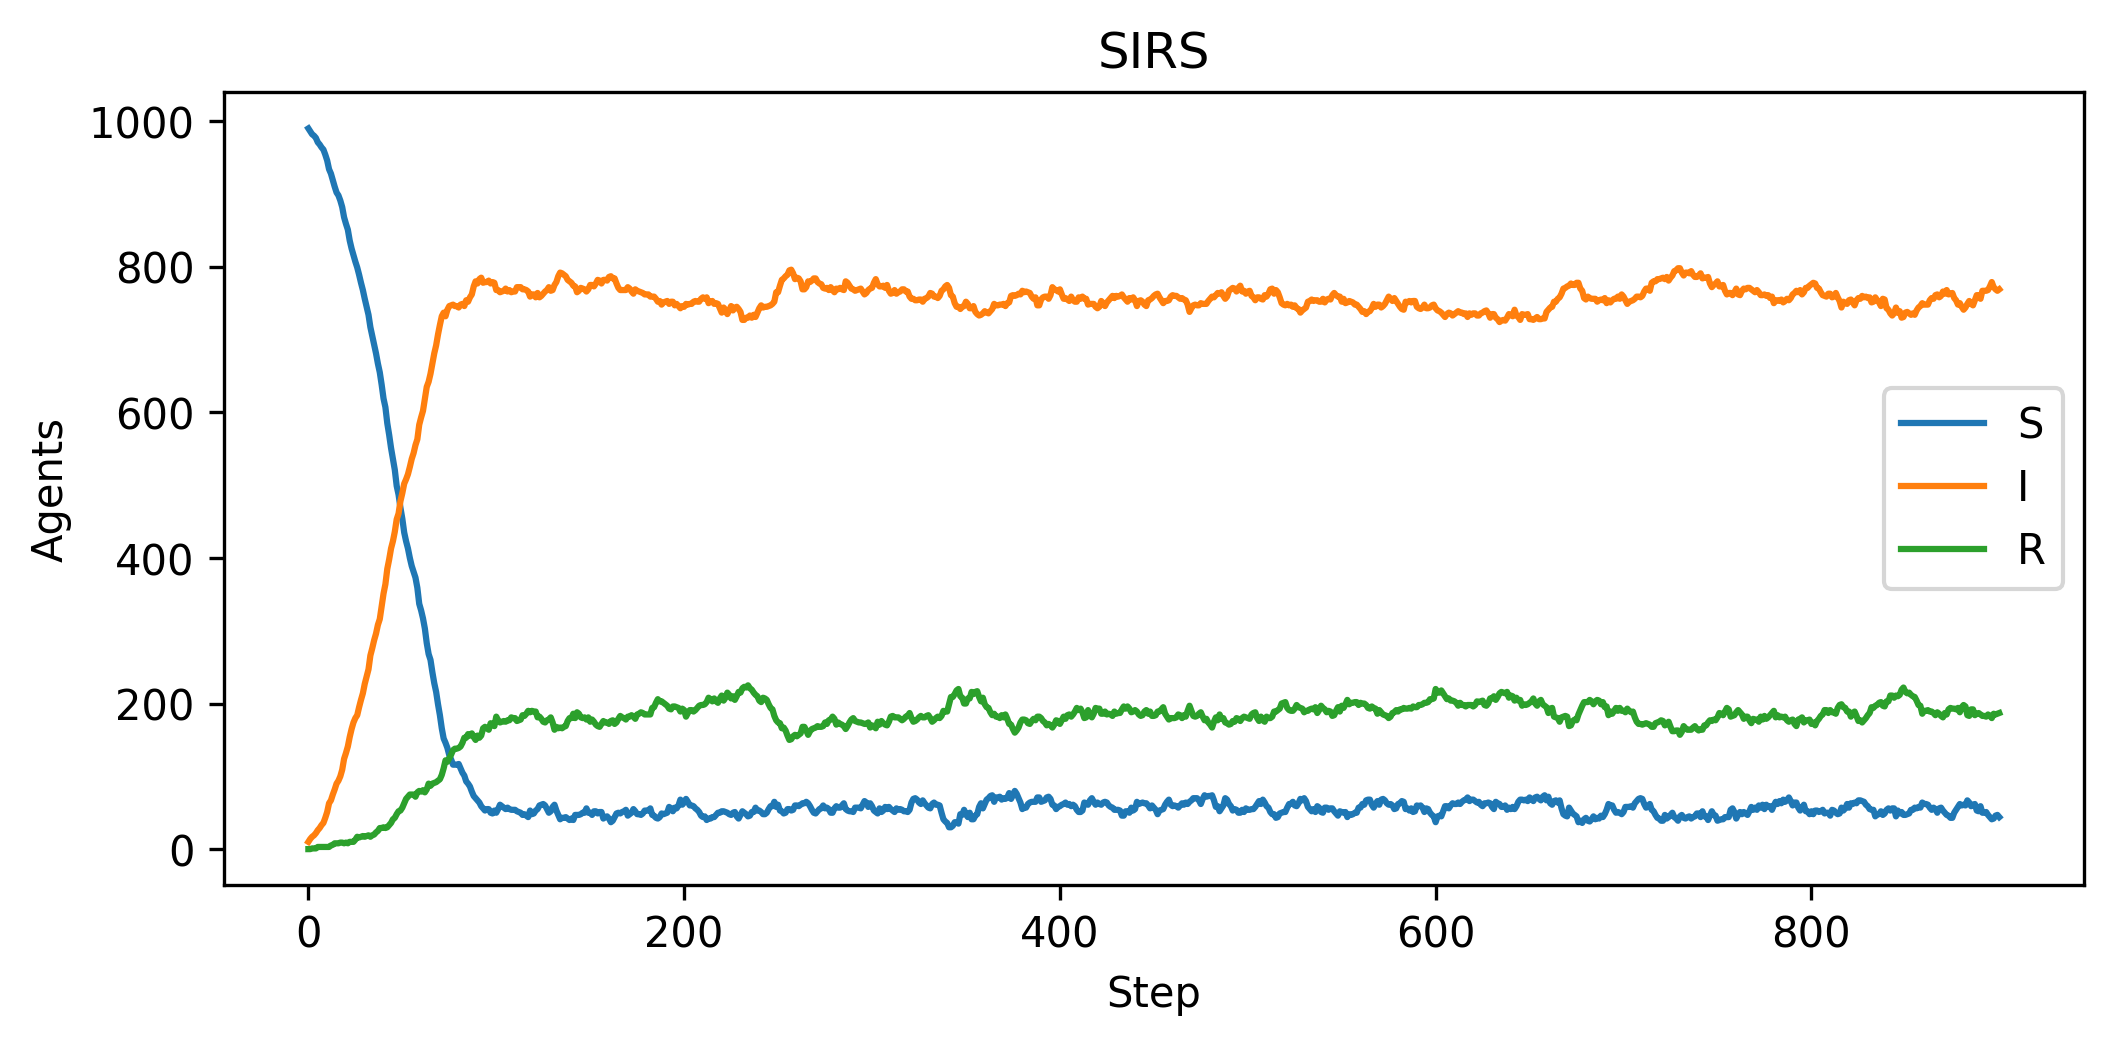

In [20]:
plt.figure(figsize=(8, 3.5), dpi=300)

for name in "SIR":
    plt.plot(
        sirs["time"], sirs[name], label=name
    )
plt.xlabel("Step")
plt.ylabel("Agents")
plt.title("SIRS")

plt.legend()
plt.show()

<a id="questions"></a>
## Questions

- [Q5: SIR - final number of recovered agents](#q5)

- [Q6: SIR - parameter study](#q6)

- [Q7: SIRD - mortality rate](#q7)

- [Q8: SIRS - temporary immunity](#q8)



<a id="q5"></a>
### Q5: SIR - final number of recovered agents

Refer to the part for **Exercise 11.2**

[Go back to questions](#questions)

**a.** Why in the ODE-based SIR model, $R_{\infty}$  depends only on the ratio $\beta/\gamma$, and in the agent-based SIR model this is not the case? Explain your reasoning.

**b.** Compare the two trends for $R_{\infty}$ seen in the plot $R_{\infty}$ vs $\beta$. Why are they different? Does it makes sense that $R_{\infty}$ is higher for smaller $\gamma$ ?

**c.** Compare the two trends for $R_{\infty}$ seen in the plot $R_{\infty}$ vs $\beta/\gamma$. Why are they different? How were they obtained? Explain.



<a id="q6"></a>
### Q6: SIR - parameter study

Refer to the figure showing $R_{\infty}$ for several different combination of $\beta$ and $\gamma$.

[Go back to questions](#questions)

**a.** Use the figure to show that, in the agent-based SIR model, $R_{\infty}$ does not only depend on  the ratio $\beta / \gamma$. Explain your reasoning.

**b.** In the code, you find:
```python
beta_grid = np.linspace(0.1, 0.9, 9)
ratio_grid = np.linspace(10, 90, 9)
```
and `gamma` is obtained inside the cycle with `gamma = beta / ratio`.

I decide to use, instead:
```python
beta_grid = np.linspace(0.1, 0.9, 9)
gamma_grid = np.linspace(0.01, 0.09, 9)
```
How would you modify the code? Would the plot be the same? Explain.


**c.** In the code, you find:
```python
beta_grid = np.linspace(0.1, 0.9, 9)
ratio_grid = np.linspace(10, 90, 9)
```
and `gamma` is obtained inside the cycle with `gamma = beta / ratio`.

I want to explore a different interval for `ratio`. I want to use:
```python
beta_grid = np.linspace(0.1, 0.9, 9)
ratio_grid = np.linspace(0.1, 0.9, 9)
```
Does this make sense? Explain your reasoning.



<a id="q7"></a>
### Q7: SIRD - mortality rate

[Go back to questions](#questions)

**a.** Assume that the mortality rule in the SIRD model is modifies as follows: first you check whether an agent dies or not, and only if it survives it can spread the disease. Indicate how to modify the module to implement this.

**b.** Is it correct to say that a low mortality rate always causes a larger number of deaths than a high mortality rate? Explain your reasoning.

**c.** Assume to substitute the deceased agents in the SIRD model with new susceptible agents. What do you expect will happen in the simulation?




<a id="q8"></a>
### Q8: SIRS - temporary immunity

[Go back to questions](#questions)

**a.** Assume to have both temporary immunity with a mortality rate $\mu > 0$ at the same time. How would you implement the different steps? Explain.

**b.** Assume a model where there are two diseased spreading at the same time, each with its own $\alpha$, $\beta$, $\gamma$. How would you modify the `step_agent` function to allow for this extension? 

**c.** Assume that catching diseases "1" gives, once recovered, temporary immunity also for diseases "2", but not viceversa. How would the evolution of the two disease be in such a case? 

